# An Oracle for Shor's Algorithm

**Erdős Institute Quantum Computing Bootcamp, Mini-project 1**

## 1. Introduction

Shor's factoring algorithm reduces integer factorization to finding the multiplicative order of an integer $a$ modulo $N$, where $\gcd(a,N)=1$.

The quantum order-finding procedure uses controlled powers of the modular multiplication operator

$$
U_a|y\rangle =
\begin{cases}
|ay \bmod N\rangle, & 0\le y<N,\\
|y\rangle, & N\le y<2^n,
\end{cases}
$$

where $n=\lceil \log_2 N\rceil$.

The objective of this project is to construct a reversible controlled implementation of $U_a$, satisfying

$$
|c\rangle|y\rangle|0\rangle_w
\longmapsto
|c\rangle|g_{a,N}(c,y)\rangle|0\rangle_w,
$$

where

$$
g_{a,N}(c,y)=
\begin{cases}
ay\bmod N, & c=1,\ y<N,\\
y, & \text{otherwise}.
\end{cases}
$$

We follow the modular arithmetic construction of Beauregard, *Circuit for Shor's Algorithm Using 2n+3 Qubits* (2003).

The implementation proceeds through Fourier-space addition, modular addition, controlled modular multiplication, and finally an in-place multiplication oracle using modular inverses and uncomputation.

We focus on $N=15$ and implement all multipliers

$$
a\in(\mathbb{Z}/15\mathbb{Z})^\times
=\{1,2,4,7,8,11,13,14\}.
$$

Our implementation also handles the out-of-range computational-basis state $y=15$, which must remain unchanged.

**Reference:** Stéphane Beauregard, [Circuit for Shor's Algorithm Using 2n+3 Qubits](https://arxiv.org/abs/quant-ph/0205095).

In [1]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Operator, Statevector

from erdos_project_1.controlled_multiplier import controlled_multiply
from erdos_project_1.fourier_adder import phi_add
from erdos_project_1.modular_adder import controlled_modular_add
from erdos_project_1.modular_multiplier import controlled_modular_multiply


## 2. Fourier Adder

The first gate we implement is the **Fourier adder**. Given a classical integer $a$, our Fourier adder, denoted by $\phi\mathrm{ADD}_a$, performs addition by $a$ in the Fourier basis. That is, it maps the input $|\phi(b)\rangle$ to $|\phi(a+b)\rangle$.

More precisely, let $N$ be the modulus and $n=\lceil\log_2 N\rceil$. We first encode $b$ using $n$ qubits and append an additional most significant qubit initialized to $|0\rangle$. Applying the QFT to the resulting $(n+1)$-qubit register gives

$$
|\phi(b)\rangle
:=F_{2^{n+1}}|b\rangle
=\frac{1}{\sqrt{2^{n+1}}}
\sum_{y=0}^{2^{n+1}-1}
e^{2\pi i by/2^{n+1}}|y\rangle.
$$

The Fourier adder implements

$$
\boxed{
\phi\mathrm{ADD}_a|\phi(b)\rangle
=|\phi(a+b)\rangle
=|\phi((a+b)\bmod 2^{n+1})\rangle.
}
$$

The additional qubit will allow us to detect the sign of intermediate subtraction results in the subsequent modular-adder construction.

Since $a$ is known classically, we can compute the necessary phase rotations explicitly, without introducing a quantum register for $a$. Writing

$$
y=\sum_{j=0}^{n}2^jy_j,\qquad y_j\in\{0,1\},
$$

we see that addition by $a$ amounts to applying a single-qubit phase gate

$$
P\left(\frac{2\pi a}{2^{n+1-j}}\right)
$$

to each qubit $j$. Thus, the Fourier adder requires only $n+1$ single-qubit phase gates and no carry operations.




### 2.1. Derivation of the Fourier Adder

We now derive the phase gates used in the Fourier adder.

Recall that our Fourier register contains $n+1$ qubits, and its Fourier-encoded state is

$$
|\phi(b)\rangle
=
\frac{1}{\sqrt{2^{n+1}}}
\sum_{y=0}^{2^{n+1}-1}
e^{2\pi i by/2^{n+1}}|y\rangle.
$$

Writing $y$ in binary,

$$
y=\sum_{j=0}^{n}2^j y_j,
\qquad y_j\in\{0,1\},
$$

we obtain

$$
\begin{aligned}
|\phi(b)\rangle
&=\frac{1}{\sqrt{2^{n+1}}}
\sum_{y_0,\ldots,y_n\in\{0,1\}}
e^{2\pi i b(\sum_{j=0}^n 2^jy_j)/2^{n+1}}
|y_n\cdots y_0\rangle\\[6pt]
&=\frac{1}{\sqrt{2^{n+1}}}
\sum_{y_0,\ldots,y_n\in\{0,1\}}
\left(
\prod_{j=0}^{n}
e^{2\pi i b y_j/2^{n+1-j}}
\right)
|y_n\cdots y_0\rangle\\[6pt]
&=
\bigotimes_{j=n}^{0}
\left(
\frac{|0\rangle+
e^{2\pi i b/2^{n+1-j}}|1\rangle}{\sqrt{2}}
\right).
\end{aligned}
$$

The last equality follows from the distributivity of tensor products over sums. In particular, the QFT of a computational-basis state is a tensor product of single-qubit states.

Now consider addition by the classical integer $a$. Replacing $b$ by $a+b$, we have

$$
\begin{aligned}
|\phi(a+b)\rangle
&=
\bigotimes_{j=n}^{0}
\frac{|0\rangle+
e^{2\pi i(a+b)/2^{n+1-j}}|1\rangle}{\sqrt{2}}\\[6pt]
&=
\bigotimes_{j=n}^{0}
\frac{|0\rangle+
e^{2\pi i a/2^{n+1-j}}
e^{2\pi i b/2^{n+1-j}}|1\rangle}{\sqrt{2}}.
\end{aligned}
$$

Therefore, on each qubit $j$, addition by $a$ amounts to applying the phase gate

$$
P(\theta_j)=
\begin{pmatrix}
1&0\\
0&e^{i\theta_j}
\end{pmatrix},
\qquad
\theta_j=\frac{2\pi a}{2^{n+1-j}}.
$$

Hence,

$$
\boxed{
\phi\mathrm{ADD}_a
=
\bigotimes_{j=n}^{0}
P\left(\frac{2\pi a}{2^{n+1-j}}\right).
}
$$



### 2.2. Interpretation

The Fourier transform converts the addition operation into a diagonal operator. Since $a$ is known classically, we can compute all phase angles $\theta_j$ beforehand and apply the corresponding phase gates independently to each qubit.

Consequently, we do not need a quantum register for $a$, nor do we need to implement carry operations.

Furthermore, the phases are periodic modulo $2^{n+1}$:

$$
e^{2\pi i(b+2^{n+1})/2^{n+1-j}}
=
e^{2\pi i b/2^{n+1-j}}.
$$

Thus, the Fourier adder naturally implements addition modulo $2^{n+1}$.

In Qiskit, we use the convention that `q[0]` is the least significant bit. Accordingly, qubit `q[j]` receives the phase rotation

$$
\boxed{\theta_j=\frac{2\pi a}{2^{n+1-j}}.}
$$

This gives our implementation of `phi_add(a, num_qubits)`, where `num_qubits = n + 1`. The implementation is stored in `fourier_adder.py` and imported below.


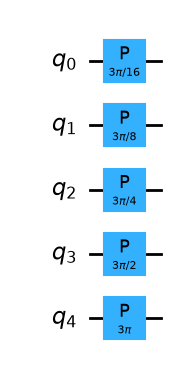

In [2]:
a = 3
n = 4

qc = phi_add(a, n + 1)
display(qc.draw("mpl"))


### 2.4. Inverse Fourier Adder and Comparison

The inverse Fourier adder performs subtraction by a classical integer $a$. Since $P(\theta)^{-1}=P(-\theta)$, we have

$$
\boxed{
\phi\mathrm{ADD}_a^{-1}=\phi\mathrm{ADD}_{-a}.
}
$$

Thus,

$$
\phi\mathrm{ADD}_a^{-1}|\phi(b)\rangle
=|\phi(b-a)\rangle,
$$

where subtraction is understood modulo $2^{n+1}$.

An important application of this operation is **comparison**. Suppose $0\leq a,b<2^n$. After applying the inverse Fourier adder followed by the inverse QFT, we obtain

$$
|\phi(b)\rangle
\xrightarrow{\phi\mathrm{ADD}_{-a}}
|\phi(b-a)\rangle
\xrightarrow{\mathrm{QFT}^{-1}}
|(b-a)\bmod 2^{n+1}\rangle.
$$

The most significant bit of this register determines whether the subtraction was negative:

$$
\operatorname{MSB}(b-a)=
\begin{cases}
1,&b<a,\\
0,&b\geq a.
\end{cases}
$$

Here the MSB is taken from the $(n+1)$-bit representation of $(b-a)\bmod 2^{n+1}$.

This comparison mechanism will be used repeatedly in our modular-adder construction to determine whether modular correction is necessary and to uncompute auxiliary qubits.



### 2.5. Verification

We now verify that our implementation of the Fourier adder agrees with the expected unitary transformation.

Let $M=2^{n+1}$ and define the ordinary addition operator $T_a$ on computational-basis states by

$$
T_a|b\rangle=|(a+b)\bmod M\rangle.
$$

Since $|\phi(b)\rangle=F_M|b\rangle$, the Fourier adder $A_a=\phi\mathrm{ADD}_a$ must satisfy

$$
A_a F_M|b\rangle=F_M T_a|b\rangle.
$$

As this holds for every computational-basis vector, we obtain

$$
\boxed{A_a=F_M T_a F_M^{-1}.}
$$

We construct the matrices $F_M$ and $T_a$ independently using NumPy and compare $F_M T_a F_M^{-1}$ with the unitary matrix of our Qiskit implementation.

This allows us to verify the full unitary, including relative phases, without implementing the multiqubit addition operator $T_a$ as a quantum circuit.

We also verify that the inverse Fourier adder satisfies

$$
\boxed{A_{-a}A_a=I.}
$$

Numerical comparisons use an absolute tolerance of $10^{-10}$ to account for floating-point errors.


In [5]:
from erdos_project_1.fourier_adder import phi_add

# Parameters
n = 4
a = 3
M = 2 ** (n + 1)

# Construct the Fourier transform matrix independently
x = np.arange(M)
F = np.exp(2j * np.pi * np.outer(x, x) / M) / np.sqrt(M)

# Construct the classical addition permutation matrix
T = np.zeros((M, M), dtype=complex)

for b in range(M):
    T[(a + b) % M, b] = 1

# Expected Fourier adder
expected = F @ T @ F.conj().T

# Actual Fourier adder from our Qiskit circuit
actual = Operator(phi_add(a, n + 1)).data

# Compare the two unitaries
error = np.max(np.abs(actual - expected))

print(f"Maximum matrix error: {error:.3e}")
assert np.allclose(actual, expected, atol=1e-10)

# Verify the inverse Fourier adder
inverse = Operator(phi_add(-a, n + 1)).data

inverse_error = np.max(np.abs(inverse @ actual - np.eye(M)))

print(f"Inverse consistency error: {inverse_error:.3e}")
assert np.allclose(inverse @ actual, np.eye(M), atol=1e-10)

print("All Fourier adder verification checks passed.")

Maximum matrix error: 2.864e-15
Inverse consistency error: 2.220e-16
All Fourier adder verification checks passed.



## 3. Modular Adder

### 3.1. Mathematical Construction

Having constructed the Fourier adder, we now use it to implement addition modulo $N$, following Beauregard's construction.

Recall that $n=\lceil\log_2 N\rceil$, and we use an $(n+1)$-qubit Fourier register to represent an integer $0\leq b<N$.

Given a classical integer $0\leq a<N$, our goal is to construct a modular adder satisfying

$$
\phi\mathrm{ADD}(a)\mathrm{MOD}(N)
|\phi(b)\rangle|0\rangle
=
|\phi((a+b)\bmod N)\rangle|0\rangle.
$$

The additional qubit $|0\rangle$ on the right is a work ancilla, distinct from the extra most significant qubit in our Fourier register.

Since $0\leq a,b<N$, modular addition has two cases:

$$
(a+b)\bmod N=
\begin{cases}
a+b,&a+b<N,\\
a+b-N,&a+b\geq N.
\end{cases}
$$

We begin by applying $\phi\mathrm{ADD}_a$, followed by $\phi\mathrm{ADD}_{-N}$:

$$
|\phi(b)\rangle
\longrightarrow
|\phi(a+b)\rangle
\longrightarrow
|\phi(a+b-N)\rangle.
$$

To determine whether subtracting $N$ was necessary, we apply the inverse QFT:

$$
|\phi(a+b-N)\rangle
\xrightarrow{\mathrm{QFT}^{-1}}
|(a+b-N)\bmod 2^{n+1}\rangle.
$$

The most significant bit (MSB) of this register indicates whether $a+b-N$ is negative:

$$
f=
\begin{cases}
1,&a+b<N,\\
0,&a+b\geq N.
\end{cases}
$$

This works because $-N\leq a+b-N<N$ lies within the signed range of the $(n+1)$-bit register.

We copy this flag into a clean ancilla using a CNOT gate, with the MSB as control and the ancilla as target. Importantly, no measurement is performed.

After applying the QFT again, we conditionally add $N$ back whenever the ancilla equals $1$.

Thus, the arithmetic register contains the desired result

$$
r=(a+b)\bmod N.
$$

At this stage, however, the joint state is

$$
\boxed{|\phi(r)\rangle|f\rangle.}
$$

Although the modular addition is correct, the ancilla still contains information about the intermediate computation. We must therefore uncompute this flag before the circuit is complete.



### 3.2. Ancilla Uncomputation

After the first half of the modular adder, we have obtained

$$
|\phi(r)\rangle|f\rangle,
\qquad
r=(a+b)\bmod N,
$$

where

$$
f=
\begin{cases}
1,&a+b<N,\\
0,&a+b\geq N.
\end{cases}
$$

Although the arithmetic register now contains the correct modular sum, the work ancilla still stores the result of our comparison. We must restore this ancilla to $|0\rangle$ without changing $r$.

The key observation is that, for $0\leq a,b<N$,

$$
\boxed{a+b<N\iff r\geq a.}
$$

Indeed, if $a+b<N$, then $r=a+b$, so $r-a=b\geq0$. Conversely, if $a+b\geq N$, then $r=a+b-N$, giving $r-a=b-N<0$.

Consequently,

$$
f=1-\operatorname{MSB}\left((r-a)\bmod 2^{n+1}\right).
$$

We can therefore reconstruct the flag from the final arithmetic result.

Starting with $|\phi(r)\rangle|f\rangle$, we apply the inverse Fourier adder $\phi\mathrm{ADD}_{-a}$, followed by the inverse QFT:

$$
|\phi(r)\rangle|f\rangle
\longrightarrow
|\phi(r-a)\rangle|f\rangle
\longrightarrow
|(r-a)\bmod 2^{n+1}\rangle|f\rangle.
$$

Let $h$ denote the MSB of this computational-basis register. By the identity above, $f=1-h$.

We apply an X gate to the MSB, followed by a CNOT from the MSB to the ancilla, and finally another X gate to restore the original MSB. The ancilla then transforms as

$$
|f\rangle
\longmapsto
|f\oplus(1-h)\rangle
=|f\oplus f\rangle
=|0\rangle.
$$

Finally, applying the QFT followed by $\phi\mathrm{ADD}_a$ restores the arithmetic register:

$$
|(r-a)\bmod 2^{n+1}\rangle|0\rangle
\longrightarrow
|\phi(r-a)\rangle|0\rangle
\longrightarrow
|\phi(r)\rangle|0\rangle.
$$

Thus, we have implemented

$$
\boxed{
|\phi(b)\rangle|0\rangle
\longmapsto
|\phi((a+b)\bmod N)\rangle|0\rangle.
}
$$

The ancilla has been **uncomputed** while preserving the desired result.

#### The doubly controlled case

In the complete circuit, the additions by $a$ and $-a$ are controlled by both $c_1$ and $c_2$.

When $c_1=c_2=1$, the construction above applies.

When either control is zero, these additions are omitted. The remaining operations subtract $N$, extract the underflow flag, conditionally restore $N$, and then uncompute the flag. Since $0\leq b<N$, subtracting $N$ always gives a negative result, so the correction restores $b$ and the ancilla returns to zero.

Therefore, the complete doubly controlled modular adder satisfies

$$
\boxed{
|c_1,c_2\rangle|\phi(b)\rangle|0\rangle
\longmapsto
|c_1,c_2\rangle|\phi(r)\rangle|0\rangle,
}
$$

where

$$
r=
\begin{cases}
(a+b)\bmod N,&c_1=c_2=1,\\
b,&\text{otherwise}.
\end{cases}
$$

This construction performs modular addition coherently and returns the work ancilla to its initial state, allowing it to be reused in subsequent arithmetic operations.



### 3.3. Implementation

We implement the doubly controlled modular adder following Figure 5 of Beauregard's construction, using our previously implemented Fourier adder as the basic building block.

The circuit consists of three main components:

1. **Modular correction:** Apply the doubly controlled Fourier addition by $a$, subtract $N$, and use the most significant bit to determine whether $N$ must be added back.
2. **Ancilla uncomputation:** Temporarily subtract $a$, reconstruct the comparison flag from the arithmetic register, and erase the work ancilla.
3. **Restoration:** Return the arithmetic register to its Fourier encoding with the correct modular sum.

We use the following register convention:

- `q[0]` and `q[1]` are the two control qubits.
- `q[2]` through `q[n+2]` form the $(n+1)$-qubit Fourier arithmetic register, ordered from least significant to most significant.
- `q[n+3]` is the clean work ancilla.

The circuit therefore requires $n+4$ qubits in total. In particular, for $N=15$, we have $n=4$, giving an eight-qubit circuit.

The QFT and inverse QFT are provided by Qiskit. The Fourier additions and conditional phase rotations are assembled using our own implementation.
The doubly controlled modular adder is implemented in
`src/erdos_project_1/modular_adder.py`, with the main function
`controlled_modular_add(a, N)`. It builds on the Fourier adder
implemented in Section 2.


We import the circuit below and visualize it for $a=3$ and $N=15$.


Number of qubits: 8
Circuit depth: 61


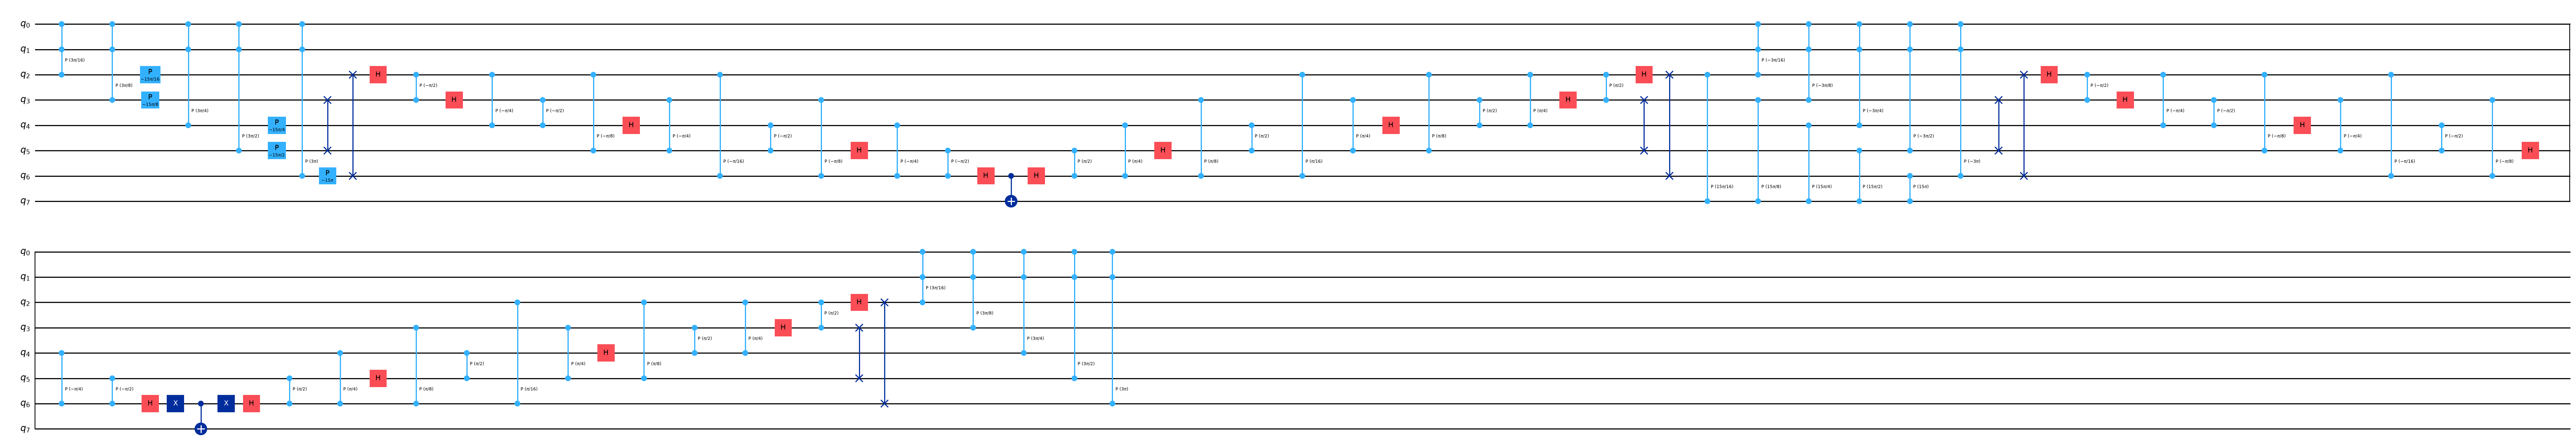

In [6]:
# Example parameters
N = 15
a = 3

# Construct the doubly controlled modular adder
mod_adder = controlled_modular_add(a, N)

print(f"Number of qubits: {mod_adder.num_qubits}")
print(f"Circuit depth: {mod_adder.depth()}")

display(mod_adder.draw("mpl", fold=100))


### 3.4. Verification

We verify that the doubly controlled modular adder implements the desired transformation

$$
|c_1,c_2\rangle|\phi(b)\rangle|0\rangle
\longmapsto
|c_1,c_2\rangle|\phi(r)\rangle|0\rangle,
$$

where

$$
r=
\begin{cases}
(a+b)\bmod N,&c_1=c_2=1,\\
b,&\text{otherwise}.
\end{cases}
$$

Unlike the Fourier adder, the modular adder uses an additional work ancilla and performs comparisons in the computational basis. We must therefore verify not only the arithmetic result but also that the control qubits are preserved and the ancilla returns to $|0\rangle$.

For each choice of $a$, $b$, and the two controls, we prepare the input state by initializing the computational register to $|b\rangle$ and then applying the QFT. After applying the modular adder, we use the inverse QFT to read the result in the computational basis.

We compare the resulting statevector with the expected basis state, including its complex amplitude. This checks the exact transformation, rather than merely comparing measurement probabilities.

Our automated tests cover all $0\leq b<N$, all $0\leq a<N$, and all four control configurations. Since the circuit is linear, correctness on these basis inputs also establishes correctness for their superpositions, provided the phases are correct.


In [8]:
import numpy as np
from qiskit.synthesis import synth_qft_full

from erdos_project_1.modular_adder import controlled_modular_add

N = 15
a = 3
b = 7
c1, c2 = 1, 1

n = (N - 1).bit_length()
m = n + 1

arithmetic = list(range(2, m + 2))
ancilla = m + 2

qc = QuantumCircuit(m + 3)

# Initialize controls
if c1:
    qc.x(0)
if c2:
    qc.x(1)

# Initialize |b> in the arithmetic register
for j in range(n):
    if (b >> j) & 1:
        qc.x(arithmetic[j])

# Encode b in the Fourier basis
qft = synth_qft_full(m, do_swaps=True)
qc.compose(qft, qubits=arithmetic, inplace=True)

# Apply the modular adder
qc.compose(
    controlled_modular_add(a, N),
    qubits=range(m + 3),
    inplace=True,
)

# Decode the arithmetic register
qc.compose(qft.inverse(), qubits=arithmetic, inplace=True)

# Compare with the expected computational-basis state
result = Statevector.from_instruction(qc)

r = (a + b) % N if c1 and c2 else b

expected_index = c1 + (c2 << 1) + (r << 2)

expected = np.zeros(2 ** (m + 3), dtype=complex)
expected[expected_index] = 1.0

error = np.max(np.abs(result.data - expected))

print(f"Expected result: {r}")
print(f"Maximum statevector error: {error:.3e}")

assert np.allclose(result.data, expected, atol=1e-10, rtol=0)

print("Modular adder verification passed.")

Expected result: 10
Maximum statevector error: 2.920e-15
Modular adder verification passed.



## 4. Controlled Modular Multiplication

### 4.1. Mathematical Construction

We now construct the controlled modular multiplication circuit of Figure 6 in Beauregard's paper using the doubly controlled modular adder from Section 3.

Let $0\leq x<N$ be an integer represented by an $n$-qubit register, where

$$
n=\lceil\log_2 N\rceil.
$$

Writing $x$ in binary gives

$$
x=\sum_{j=0}^{n-1}2^j x_j,
\qquad x_j\in\{0,1\}.
$$

For a fixed classical integer $a$, we therefore have

$$
ax\bmod N
=
\left(\sum_{j=0}^{n-1}x_j(2^ja\bmod N)\right)\bmod N.
$$

Define the classical constants

$$
a_j=(2^ja)\bmod N.
$$

Our goal is to construct a controlled modular multiply-accumulate circuit acting on three registers:

- A control qubit $|c\rangle$.
- An $n$-qubit input register $|x\rangle$.
- An $(n+1)$-qubit accumulator $|b\rangle$, where $0\leq b<N$.

The desired transformation is

$$
\boxed{
|c\rangle|x\rangle|b\rangle
\longmapsto
|c\rangle|x\rangle|(b+cax)\bmod N\rangle.
}
$$

Here the multiplication by $c\in\{0,1\}$ expresses the controlled operation: when $c=0$, the accumulator is unchanged.

We begin by applying the QFT to the accumulator:

$$
|b\rangle\longmapsto|\phi(b)\rangle.
$$

For each input bit $x_j$, we apply the doubly controlled modular adder from Section 3, using $c$ and $x_j$ as its two control qubits, and $a_j$ as its classical addend:

$$
|\phi(b_j)\rangle
\longmapsto
|\phi((b_j+cx_ja_j)\bmod N)\rangle.
$$

After all $n$ additions, the accumulator contains

$$
\left|\phi\left(
b+\sum_{j=0}^{n-1}cx_ja_j
\bmod N
\right)\right\rangle
=
|\phi((b+cax)\bmod N)\rangle.
$$

Finally, applying the inverse QFT gives the desired computational-basis result.

Each modular adder returns its work ancilla to $|0\rangle$, so all $n$ additions can reuse the same ancilla.

In particular, if the accumulator is initialized to $|0\rangle$, the circuit computes

$$
\boxed{
|c\rangle|x\rangle|0\rangle
\longmapsto
|c\rangle|x\rangle|cax\bmod N\rangle.
}
$$

This is a reversible multiply-accumulate operation, not yet an in-place multiplication of $x$. The input register remains unchanged, and the product is stored in a separate accumulator.

In Section 5, we will use the inverse multiplier and controlled swaps to remove this additional register's contents and obtain the clean in-place oracle required for Shor's algorithm.



### 4.2. Implementation

We implement the controlled modular multiply-accumulate circuit by composing the doubly controlled modular adders from Section 3.

The circuit uses:

- One external control qubit $c$.
- An $n$-qubit input register $x$.
- An $(n+1)$-qubit accumulator.
- One reusable work ancilla.

The total register size is $2n+3$ qubits.

We first apply the QFT to the accumulator. For each bit $x_j$, we then add

$$
a_j=(2^ja)\bmod N
$$

modulo $N$, controlled jointly by $c$ and $x_j$. Finally, we apply the inverse QFT. 

The controlled modular multiply-accumulate circuit is implemented in
`src/erdos_project_1/controlled_multiplier.py`, with the main function
`controlled_multiply(a, N)`. It constructs the multiplier by composing
the doubly controlled modular adders from Section 3.


**Example.** For $N=15$ and $a=7$, the four modular addends are

$$
(a_0,a_1,a_2,a_3)=(7,14,13,11).
$$

If $x=6=0110_2$ and $c=1$, only the additions controlled by $x_1$ and $x_2$ are activated:

$$
0\xrightarrow{+14}14\xrightarrow{+13}12\pmod{15}.
$$

Thus, the accumulator contains

$$
7\cdot6\bmod15=12.
$$

The input register and control qubit remain unchanged, and the shared work ancilla returns to $|0\rangle$.


Modular addends: [7, 14, 13, 11]
Number of qubits: 11
Circuit depth: 264
Active addends for x=6: [14, 13]
Expected product: 12


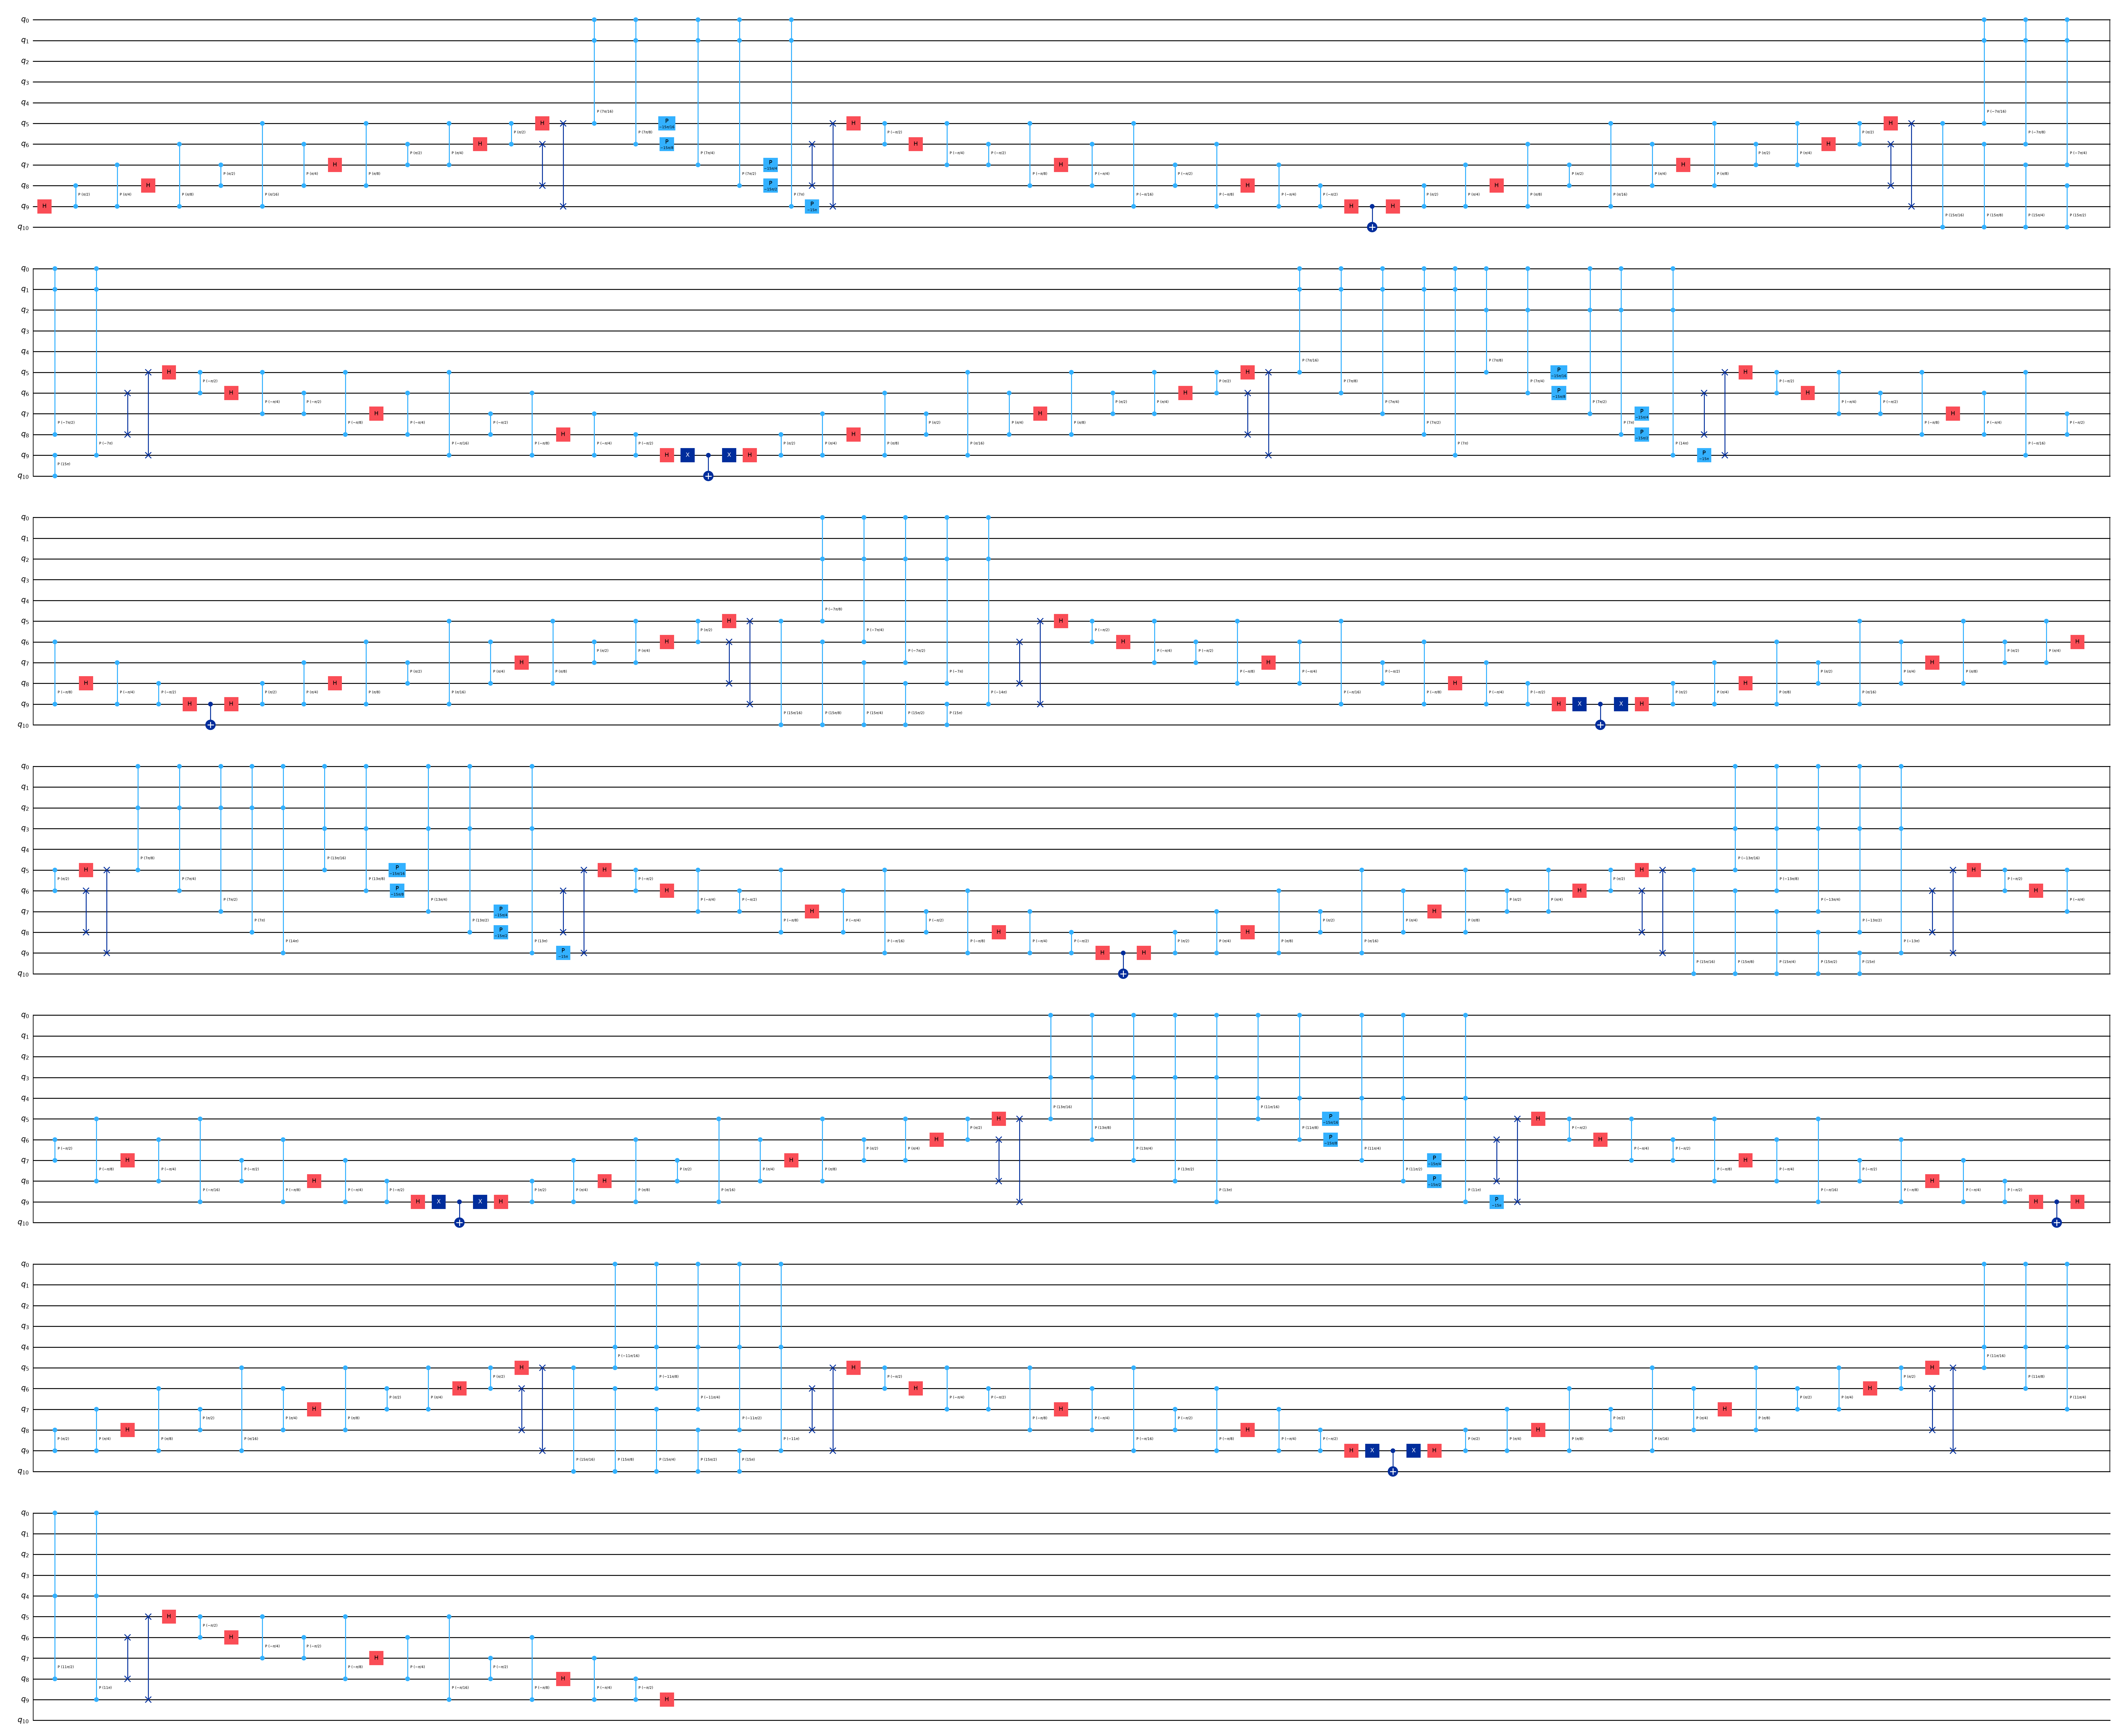

In [9]:
N = 15
a = 7

multiplier = controlled_multiply(a, N)

n = (N - 1).bit_length()
addends = [(a * 2**j) % N for j in range(n)]

print("Modular addends:", addends)
print("Number of qubits:", multiplier.num_qubits)
print("Circuit depth:", multiplier.depth())

# Illustrative input x = 6
x = 6
active_addends = [addends[j] for j in range(n) if (x >> j) & 1]

print("Active addends for x=6:", active_addends)
print("Expected product:", sum(active_addends) % N)

display(multiplier.draw("mpl", fold=100))


### 4.3. Verification

We verify the controlled modular multiply-accumulate circuit implemented in `src/erdos_project_1/controlled_multiplier.py`.

For $0\leq x,b<N$, the expected operation is

$$
|c\rangle|x\rangle|b\rangle|0\rangle
\longmapsto
|c\rangle|x\rangle|(b+cax)\bmod N\rangle|0\rangle.
$$

The last qubit is the reusable work ancilla.

Our verification checks four properties:

1. **Arithmetic correctness:** The accumulator contains $(b+cax)\bmod N$.
2. **Control behavior:** When $c=0$, the circuit acts as the identity on the data registers.
3. **Register preservation:** The control qubit and input register $x$ remain unchanged.
4. **Ancilla cleanup and phases:** The work ancilla returns to $|0\rangle$, and the complete output state agrees with the expected state, including complex amplitudes.

We prepare computational-basis inputs, apply the controlled multiplier, and compare its full output statevector against the expected computational-basis state.

In the automated tests, we cover both control values, all $0\leq x,b<15$, and every multiplier $a$ coprime to $15$.

Comparing exact amplitudes on all these basis states also establishes the correct action on arbitrary superpositions within the valid input subspace, by linearity.


In [10]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

from erdos_project_1.controlled_multiplier import controlled_multiply

N = 15
a = 7
x = 6
b = 0
c = 1

n = (N - 1).bit_length()
m = n + 1

# Register layout:
# q[0]           : external control
# q[1:n+1]       : input x
# q[n+1:2n+2]    : accumulator b (n+1 qubits)
# q[2n+2]        : work ancilla

qc = QuantumCircuit(2 * n + 3)

if c:
    qc.x(0)

for j in range(n):
    if (x >> j) & 1:
        qc.x(1 + j)

for j in range(m):
    if (b >> j) & 1:
        qc.x(n + 1 + j)

# Apply our controlled multiplier
qc.compose(controlled_multiply(a, N), inplace=True)

actual = Statevector.from_instruction(qc).data

# Compute the expected result independently
r = (b + c * a * x) % N

# Qiskit uses little-endian indexing
expected_index = c + (x << 1) + (r << (n + 1))

expected = np.zeros(2 ** (2 * n + 3), dtype=complex)
expected[expected_index] = 1.0

error = np.max(np.abs(actual - expected))

print(f"Input x: {x}")
print(f"Initial accumulator: {b}")
print(f"Expected accumulator: {r}")
print(f"Maximum statevector error: {error:.3e}")

assert np.allclose(actual, expected, atol=1e-10, rtol=0)

print("Controlled multiplier verification passed.")

Input x: 6
Initial accumulator: 0
Expected accumulator: 12
Maximum statevector error: 7.052e-15
Controlled multiplier verification passed.



## 5. Clean In-Place Controlled Modular Multiplication

### 5.1. Mathematical Construction

In Section 4, we constructed a controlled modular multiply-accumulate circuit implementing

$$
|c\rangle|x\rangle|b\rangle
\longmapsto
|c\rangle|x\rangle|(b+cax)\bmod N\rangle.
$$

Although this operation is reversible, it does not directly implement the modular multiplication oracle required for Shor's algorithm: the input register $x$ remains unchanged, while the product is stored in a separate accumulator.

Our goal is instead to implement

$$
\boxed{
U_a|c\rangle|x\rangle|0\rangle
=
\begin{cases}
|0\rangle|x\rangle|0\rangle,&c=0,\\
|1\rangle|ax\bmod N\rangle|0\rangle,&c=1,
\end{cases}
}
$$

where all additional work qubits are initialized and returned to $|0\rangle$.

We assume $\gcd(a,N)=1$, ensuring that the multiplicative inverse $a^{-1}\bmod N$ exists. Multiplication by $a$ is therefore a permutation of the residues modulo $N$.

#### Step 1. Compute the product

Starting with an accumulator initialized to zero, apply the controlled multiply-accumulate circuit $M_a$ from Section 4:

$$
|1\rangle|x\rangle|0\rangle
\xrightarrow{M_a}
|1\rangle|x\rangle|ax\bmod N\rangle.
$$

The input register is unchanged, while the accumulator contains the product.

#### Step 2. Swap the registers

Apply controlled SWAP gates between the $n$ input qubits and the $n$ low-order accumulator qubits.

When $c=1$, this produces

$$
|1\rangle|x\rangle|ax\bmod N\rangle
\longrightarrow
|1\rangle|ax\bmod N\rangle|x\rangle.
$$

Because $ax\bmod N<N<2^n$, the extra most significant accumulator qubit is zero and does not need to be swapped.

When $c=0$, the controlled SWAP gates do nothing.

#### Step 3. Uncompute the accumulator

Let $a^{-1}$ denote the multiplicative inverse of $a$ modulo $N$.

Consider the multiply-accumulate circuit $M_{a^{-1}}$, which acts as

$$
M_{a^{-1}}:
|y\rangle|b\rangle
\longmapsto
|y\rangle|(b+a^{-1}y)\bmod N\rangle.
$$

Its inverse therefore subtracts $a^{-1}y$ modulo $N$ from the accumulator.

After Step 2, the input register contains $y=ax\bmod N$, and the accumulator contains $b=x$. Hence

$$
(b-a^{-1}y)\bmod N
=
(x-a^{-1}ax)\bmod N
=0.
$$

Applying $M_{a^{-1}}^{-1}$ therefore gives

$$
|1\rangle|ax\bmod N\rangle|x\rangle
\xrightarrow{M_{a^{-1}}^{-1}}
|1\rangle|ax\bmod N\rangle|0\rangle.
$$

The accumulator has been uncomputed without disturbing the product.

Combining these steps gives

$$
\boxed{
U_a=M_{a^{-1}}^{-1}\circ\mathrm{CSWAP}\circ M_a.
}
$$

All three operations are controlled by the external qubit $c$. Consequently, when $c=0$, the complete construction acts as the identity.

#### Handling inputs outside the modular range

For $N=15$, the input register has $n=4$ qubits and can represent integers $0,\ldots,15$, although the modular multiplication construction is defined on residues $0,\ldots,14$.

To define a valid reversible oracle on the full computational basis, we choose to leave the unused state $|15\rangle$ unchanged:

$$
U_a|c\rangle|15\rangle=|c\rangle|15\rangle.
$$

We implement this by using an additional clean flag qubit that enables the multiplication only when $c=1$ and $x\neq15$.

The complete oracle thus acts as

$$
\boxed{
U_a|c\rangle|x\rangle=
\begin{cases}
|c\rangle|x\rangle,&c=0\text{ or }x=15,\\
|1\rangle|ax\bmod15\rangle,&c=1,\ 0\leq x<15.
\end{cases}
}
$$

The flag, accumulator, and arithmetic work ancilla are all returned to $|0\rangle$.



### 5.2. Implementation

The clean in-place modular multiplication oracle is implemented in
`src/erdos_project_1/modular_multiplier.py`, with the function
`controlled_modular_multiply(a, N)`.

We construct the oracle using three operations:

1. Apply the controlled multiply-accumulate circuit $M_a$ to compute $ax\bmod N$ in the accumulator.
2. Apply controlled SWAP gates between the input register and the low-order accumulator qubits.
3. Apply the inverse circuit $M_{a^{-1}}^{-1}$ to uncompute the accumulator.

For $N=15$, we additionally use a validity flag to ensure that the unused input state $|15\rangle$ is fixed. The flag is computed before multiplication and uncomputed afterward.

The complete circuit has $2n+4=12$ qubits, consisting of one external control, $n=4$ input qubits, $n+1=5$ accumulator qubits, one arithmetic work ancilla, and one validity flag.

**Example.** Let $N=15$ and $a=7$. Since

$$
7^{-1}\equiv13\pmod{15},
$$

we use $M_7$ to compute the product and $M_{13}^{-1}$ to erase the accumulator.

For $x=6$, the register evolution is

$$
|6\rangle|0\rangle
\xrightarrow{M_7}
|6\rangle|12\rangle
\xrightarrow{\mathrm{SWAP}}
|12\rangle|6\rangle
\xrightarrow{M_{13}^{-1}}
|12\rangle|0\rangle.
$$

Thus, the input register contains $7\cdot6\bmod15=12$, while all auxiliary registers are restored to zero.


Modulus: 15
Multiplier: 7
Modular inverse: 13
Number of qubits: 12
Circuit depth: 528


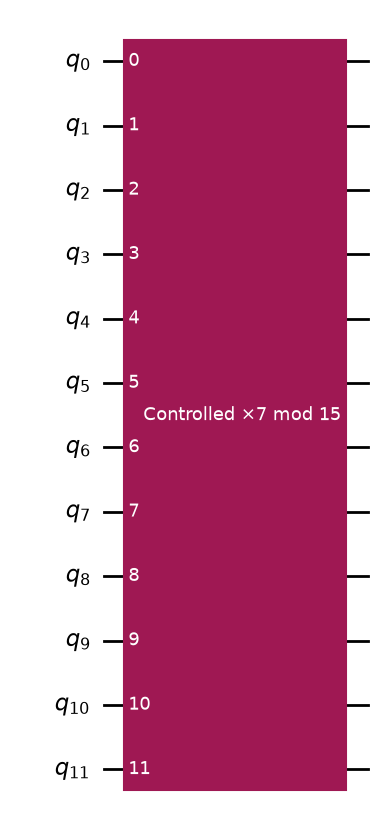

In [11]:
N = 15
a = 7

oracle = controlled_modular_multiply(a, N)

print("Modulus:", N)
print("Multiplier:", a)
print("Modular inverse:", pow(a, -1, N))
print("Number of qubits:", oracle.num_qubits)
print("Circuit depth:", oracle.depth())

# Display the top-level oracle as a labeled block.
# This keeps the notebook readable without hiding the implementation.
from qiskit import QuantumCircuit

overview = QuantumCircuit(oracle.num_qubits)
overview.append(
    oracle.to_gate(label=f"Controlled ×{a} mod {N}"),
    range(oracle.num_qubits),
)

display(overview.draw("mpl"))


### 5.3. Verification

We verify that the controlled modular multiplication oracle implemented in `src/erdos_project_1/modular_multiplier.py` satisfies

$$
U_a|c\rangle|x\rangle|0\rangle
=
\begin{cases}
|0\rangle|x\rangle|0\rangle,&c=0,\\
|1\rangle|ax\bmod15\rangle|0\rangle,&c=1,\ 0\leq x<15,\\
|1\rangle|15\rangle|0\rangle,&c=1,\ x=15.
\end{cases}
$$

Here the final zero register represents all seven auxiliary qubits: the five-qubit accumulator, the arithmetic work ancilla, and the validity flag.

We verify the following properties:

1. **Modular multiplication:** Every valid input $x$ is mapped to $ax\bmod15$ when the control is active.
2. **Control behavior:** The oracle acts as the identity when $c=0$.
3. **Out-of-range input:** The unused computational-basis state $|15\rangle$ remains unchanged.
4. **Ancilla cleanup:** All auxiliary qubits return to $|0\rangle$.
5. **Phase correctness:** The full output statevector agrees with the expected basis state, including its complex amplitude.

We test all eight multipliers $a$ satisfying $\gcd(a,15)=1$, both control states, and all sixteen computational-basis inputs.

Because these comparisons check exact amplitudes, correctness on the basis states also establishes the desired action on their arbitrary superpositions by linearity.

Finally, we verify the inverse relation

$$
U_{a^{-1}}U_a=I
$$

on the valid computational subspace, with the identity also holding on the unused state $|15\rangle$ under our chosen convention.


In [13]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

from erdos_project_1.modular_multiplier import controlled_modular_multiply

N = 15
a = 7
x = 6
c = 1

n = (N - 1).bit_length()
total_qubits = 2 * n + 4

# q[0]: control
# q[1:5]: input x
# q[5:10]: accumulator
# q[10]: arithmetic work ancilla
# q[11]: validity flag

qc = QuantumCircuit(total_qubits)

if c:
    qc.x(0)

for j in range(n):
    if (x >> j) & 1:
        qc.x(1 + j)

qc.compose(controlled_modular_multiply(a, N), inplace=True)

actual = Statevector.from_instruction(qc).data

# Expected input-register output
r = (a * x) % N if c and x < N else x

# All auxiliary qubits are expected to be zero
expected_index = c + (r << 1)

expected = np.zeros(2**total_qubits, dtype=complex)
expected[expected_index] = 1.0

error = np.max(np.abs(actual - expected))

print(f"Input x: {x}")
print(f"Expected output: {r}")
print(f"Maximum statevector error: {error:.3e}")

assert np.allclose(actual, expected, atol=1e-10, rtol=0)

print("Final oracle verification passed.")

Input x: 6
Expected output: 12
Maximum statevector error: 1.825e-14
Final oracle verification passed.



## 6. Resource Analysis

We analyze the resources required by our controlled modular multiplication oracle, implemented in `src/erdos_project_1/modular_multiplier.py`.

### 6.1. Qubit Count

For an $n$-bit modulus, the construction uses:

| Register | Qubits |
|---|---:|
| External control | $1$ |
| Input register | $n$ |
| Fourier arithmetic accumulator | $n+1$ |
| Modular-adder work ancilla | $1$ |
| Validity flag for $N=15$ | $1$ |
| **Total** | **$2n+4$** |

For $N=15$, we have $n=4$, so our implementation uses

$$
\boxed{2(4)+4=12\text{ qubits}.}
$$

The extra validity flag allows us to leave the unused computational-basis state $|15\rangle$ unchanged. Without this additional flag, the underlying Beauregard-style construction uses $2n+3$ qubits.

### 6.2. Circuit Structure

Our oracle is constructed as

$$
U_a=M_{a^{-1}}^{-1}\circ\mathrm{CSWAP}\circ M_a,
$$

where each multiply-accumulate circuit $M_a$ consists of $n$ doubly controlled modular adders.

Consequently, the in-place multiplier contains:

- $2n$ doubly controlled modular-adder applications;
- $n$ controlled SWAP gates;
- two QFTs and two inverse QFTs on $(n+1)$ qubits, before accounting for the transforms inside the modular adders;
- additional gates to compute and uncompute the validity flag.

Each modular adder itself contains Fourier additions, comparisons, and ancilla uncomputation.

Thus, the dominant arithmetic cost comes from the repeated controlled modular additions.

### 6.3. Gate Counts and Circuit Depth

We use Qiskit to measure the circuit depth and operation counts.

Since our implementation may contain composite gates, we distinguish between:

1. **Logical operations:** The higher-level gates appearing in the constructed circuit.
2. **Decomposed operations:** The gates obtained after expanding composite instructions.

Counting an entire Fourier adder as one operation would underestimate the physical gate cost. We therefore report both the original circuit statistics and statistics after decomposition.

These counts depend on the chosen gate decomposition and do not, by themselves, represent a hardware-optimized implementation.


In [19]:
from math import gcd

from erdos_project_1.modular_multiplier import controlled_modular_multiply

N = 15
valid_a = [a for a in range(1, N) if gcd(a, N) == 1]

resource_data = []

for a in valid_a:
    oracle = controlled_modular_multiply(a, N)

    # Expand composite circuit instructions.
    expanded = oracle.decompose(reps=10)

    resource_data.append(
        {
            "a": a,
            "qubits": oracle.num_qubits,
            "logical_depth": oracle.depth(),
            "logical_gates": oracle.size(),
            "expanded_depth": expanded.depth(),
            "expanded_gates": expanded.size(),
        }
    )

import pandas as pd

resources = pd.DataFrame(resource_data)
display(resources)

,a,qubits,logical_depth,logical_gates,expanded_depth,expanded_gates
0,1,12,528,852,2887,4520
1,2,12,528,852,2887,4520
2,4,12,528,852,2887,4520
3,7,12,528,852,2887,4520
4,8,12,528,852,2887,4520
5,11,12,528,852,2887,4520
6,13,12,528,852,2887,4520
7,14,12,528,852,2887,4520


In [20]:
a = 7

oracle = controlled_modular_multiply(a, N)

print("Original circuit operations:")
print(dict(oracle.count_ops()))

expanded = oracle.decompose(reps=10)

print("\nExpanded circuit operations:")
print(dict(expanded.count_ops()))

print("\nExpanded depth:", expanded.depth())
print("Expanded gate count:", expanded.size())

Original circuit operations:
{'cp': 400, 'h': 180, 'mcphase': 120, 'swap': 72, 'p': 40, 'cx': 18, 'x': 16, 'cswap': 4, 'mcx': 2}

Expanded circuit operations:
{'u': 2566, 'cx': 1954}

Expanded depth: 2887
Expanded gate count: 4520


In [21]:
oracle = controlled_modular_multiply(7, 15)

basis = ["rz", "sx", "x", "cx"]

compiled = transpile(
    oracle,
    basis_gates=basis,
    optimization_level=0,
)

print("Basis gates:", basis)
print("Gate count:", compiled.size())
print("Circuit depth:", compiled.depth())
print("Gate distribution:", dict(compiled.count_ops()))

Basis gates: ['rz', 'sx', 'x', 'cx']
Gate count: 4695
Circuit depth: 2926
Gate distribution: {'rz': 2613, 'cx': 1844, 'sx': 218, 'x': 20}


In [22]:
from math import gcd

import pandas as pd
from qiskit import transpile

from erdos_project_1.modular_multiplier import controlled_modular_multiply

N = 15
basis = ["rz", "sx", "x", "cx"]

results = []

for a in range(1, N):
    if gcd(a, N) != 1:
        continue

    oracle = controlled_modular_multiply(a, N)

    compiled = transpile(
        oracle,
        basis_gates=basis,
        optimization_level=0,
    )

    counts = compiled.count_ops()

    results.append(
        {
            "a": a,
            "qubits": compiled.num_qubits,
            "total_gates": compiled.size(),
            "depth": compiled.depth(),
            "cx": counts.get("cx", 0),
            "rz": counts.get("rz", 0),
            "sx": counts.get("sx", 0),
            "x": counts.get("x", 0),
        }
    )

resource_comparison = pd.DataFrame(results)

display(resource_comparison)

,a,qubits,total_gates,depth,cx,rz,sx,x
0,1,12,4695,2926,1844,2613,218,20
1,2,12,4695,2926,1844,2613,218,20
2,4,12,4695,2926,1844,2613,218,20
3,7,12,4695,2926,1844,2613,218,20
4,8,12,4695,2926,1844,2613,218,20
5,11,12,4695,2926,1844,2613,218,20
6,13,12,4695,2926,1844,2613,218,20
7,14,12,4695,2926,1844,2613,218,20



### 6.4. Results and Discussion

For $N=15$, we evaluated the oracle for every valid multiplier

$$
a\in\{1,2,4,7,8,11,13,14\}.
$$

All eight multipliers have identical resource counts under our implementation and decomposition settings:

| Circuit representation | Gate count | Depth |
|---|---:|---:|
| Original circuit | 852 | 528 |
| Expanded (`decompose(reps=10)`) | 4,520 | 2,887 |
| Transpiled to $\{R_Z,SX,X,CX\}$ | 4,695 | 2,926 |

Each circuit uses 12 qubits, of which seven are auxiliary qubits: a five-qubit accumulator, one modular-arithmetic work ancilla, and one validity flag.

**Multi-controlled operations.** Before decomposition, the circuit contains:

| Operation | Count | Controls |
|---|---:|---:|
| Controlled phase (`cp`) | 400 | 1 |
| Multi-controlled phase (`mcphase`) | 120 | 2 |
| Controlled X (`cx`) | 18 | 1 |
| Controlled SWAP (`cswap`) | 4 | 1 |
| Multi-controlled X (`mcx`) | 2 | 5 |

The five-controlled X gates are used to compute and uncompute the validity flag that prevents the oracle from modifying the unused input $x=15$.

**Elementary-gate decomposition.** We transpiled every multiplier into the common gate basis $\{R_Z,SX,X,CX\}$ using Qiskit with `optimization_level=0` and no connectivity constraints.

Each resulting circuit contains:

| Gate | Count |
|---|---:|
| $R_Z$ | 2,613 |
| $SX$ | 218 |
| $X$ | 20 |
| $CX$ | 1,844 |
| **Total** | **4,695** |

The uniform resource counts arise because our implementation uses the same arithmetic structure for every multiplier. Changing $a$ changes the modular-addition constants and Fourier rotation angles but not the number or arrangement of gates.

The large increase in gate count after decomposition reflects the cost of implementing controlled modular arithmetic using one- and two-qubit gates. In particular, the standardized decomposition requires 1,844 CX gates.

These resource counts are specific to our construction and chosen gate basis. They do not represent a hardware-optimized circuit, and circuit depth is measured without imposing device connectivity constraints.



## 7. Summary and Conclusion

The construction proceeds through four stages, following Beauregard's approach:

| Stage | Main operation | Qubits ($N=15$) | Purpose |
|---|---|---:|---|
| Fourier Adder (Fig. 3) | $b\mapsto b+a\pmod{32}$ in the Fourier basis | 5 | Addition through phase rotations |
| Doubly Controlled Modular Adder (Fig. 5) | $b\mapsto b+c_1c_2a\pmod{15}$ | 8 | Modular addition with clean ancilla |
| Controlled Multiply-Accumulate (Fig. 6) | $(x,b)\mapsto(x,b+cax\pmod{15})$ | 11 | Construct multiplication from modular additions |
| Clean In-Place Multiplier (Fig. 7) | $x\mapsto ax\pmod{15}$ when $c=1$ | 12 | Final oracle with all work qubits cleaned |

All four stages are implemented in our Python package and verified numerically against independent classical references.

For the final oracle, the 12 qubits consist of one control, four input qubits, five accumulator qubits, one arithmetic ancilla, and one validity flag. The last flag is our addition to ensure that the unused input $x=15$ remains unchanged.



## Appendix A. Coherence and Ancilla Uncomputation

Our exhaustive verification checks the exact action of the oracle on computational-basis inputs. Since quantum circuits are linear, this also establishes their action on arbitrary superpositions.

For an arbitrary input state

$$
|\psi\rangle=\sum_{c=0}^{1}\sum_{x=0}^{15}
\alpha_{c,x}|c\rangle|x\rangle,
$$

the final oracle satisfies

$$
U_a\left(|\psi\rangle|0\rangle_w\right)
=
\sum_{c=0}^{1}\sum_{x=0}^{15}
\alpha_{c,x}|c\rangle|g_{a,15}(c,x)\rangle|0\rangle_w,
$$

where

$$
g_{a,15}(c,x)=
\begin{cases}
ax\bmod15,&c=1,\ x<15,\\
x,&\text{otherwise}.
\end{cases}
$$

In particular, with $a=7$, $x=6$, and the control initialized to $|+\rangle$,

$$
\frac{|0\rangle+|1\rangle}{\sqrt{2}}|6\rangle|0\rangle_w
\longmapsto
\frac{|0\rangle|6\rangle+|1\rangle|12\rangle}{\sqrt{2}}
|0\rangle_w.
$$

This creates entanglement between the control and input registers, but leaves the work registers unentangled.

The cleanup of auxiliary registers is essential. An intermediate state of the form

$$
\sum_x\alpha_x|g(x)\rangle|f(x)\rangle_w
$$

may remain entangled with the workspace if $f(x)$ depends on $x$.

Our modular adders erase their comparison flags through reversible computation, while the final multiplier uses the compute–swap–uncompute construction

$$
|x\rangle|0\rangle
\xrightarrow{M_a}
|x\rangle|ax\bmod N\rangle
\xrightarrow{\mathrm{SWAP}}
|ax\bmod N\rangle|x\rangle
\xrightarrow{M_{a^{-1}}^{-1}}
|ax\bmod N\rangle|0\rangle.
$$

The validity flag for $x=15$ is also uncomputed. Consequently, all seven auxiliary qubits return to $|0\rangle$.

Although the exhaustive basis-state tests already establish coherence mathematically, we additionally verify an explicit superposition below. Comparing the full complex statevector detects unwanted relative phases and residual work entanglement.


In [23]:
from math import sqrt

import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

from erdos_project_1.modular_multiplier import controlled_modular_multiply

N, a, x = 15, 7, 6
n = 4
num_qubits = 2 * n + 4

qc = QuantumCircuit(num_qubits)

# Prepare the external control in |+>
qc.h(0)

# Prepare x = 6
for j in range(n):
    if (x >> j) & 1:
        qc.x(j + 1)

# Apply the complete oracle
qc.compose(controlled_modular_multiply(a, N), inplace=True)

actual = Statevector.from_instruction(qc).data

# Expected output:
# (|0>|6> + |1>|12>) / sqrt(2)
# All seven work qubits remain zero.
expected = np.zeros(2**num_qubits, dtype=complex)

expected[6 << 1] = 1 / sqrt(2)
expected[1 + (12 << 1)] = 1 / sqrt(2)

error = np.max(np.abs(actual - expected))

print(f"Maximum superposition error: {error:.3e}")

assert np.allclose(actual, expected, atol=1e-10, rtol=0)

print("Superposition and ancilla cleanup verified.")

Maximum superposition error: 1.310e-14
Superposition and ancilla cleanup verified.
